# 🧀 Nido Mozzarella: pronóstico de la producción mensual de queso con Machine Learning

**Data Science II: Machine Learning para la Ciencia de Datos · Coderhouse**
**Entrega Final: Entrenamiento y optimización de modelos de Machine Learning**
**Autora:** María Luján Massironi

---

## 1. Abstracto

### Motivación
**Nido Mozzarella** es una pyme que elabora y vende mozzarella. En la primera entrega analizamos el mercado en el que opera, con datos públicos del INDEC, clima, feriados e inflación. Encontramos tres cosas clave:
- La producción de quesos en Argentina es **muy estacional**: octubre produce el doble que abril.
- Cambia mucho **de un año a otro**: hubo caídas de hasta 30% y subas de 16%.
- El **precio del queso** se mueve con la oferta: es más caro cuando hay menos producción.

Con eso, la siguiente pregunta es si podemos **anticipar cuánto queso se va a producir el mes que viene**. Si Nido Mozzarella sabe con anticipación si va a haber mucha o poca oferta en el mercado, puede planificar mejor sus compras de leche, su stock y sus precios.

### Audiencia
- **Dueños y gerencia:** plan de producción y presupuesto.
- **Compras:** cuándo asegurar más leche.
- **Comercial:** cuándo hay espacio para subir precios (poca oferta) y cuándo conviene hacer promociones (mucha oferta).

## 2. Problema que buscamos resolver

> **¿Cuántas miles de toneladas de queso se van a producir en Argentina el mes que viene?**

Es un problema de **regresión**: la variable a predecir (`prod_quesos_kt`) es numérica y continua.

Preguntas que acompañan al problema principal:
1. ¿Un modelo de Machine Learning predice mejor que la regla simple de "igual que el mismo mes del año anterior"?
2. ¿Qué modelo funciona mejor: uno lineal (Ridge) o uno de ensamble (Random Forest, Gradient Boosting, XGBoost)?
3. ¿Cuánto mejora cada modelo al optimizar sus hiperparámetros?
4. ¿Qué variables pesan más en la predicción?

**Métricas de selección:**
- **RMSE** (raíz del error cuadrático medio, en miles de toneladas): es la principal, porque penaliza los errores grandes, que son los que más le cuestan al negocio.
- **MAE** (error absoluto medio).
- **R²** (proporción de la variación que explica el modelo).

## 3. Carga de datos

Usamos el dataset mensual que armamos en la primera entrega (`Nido_Mozzarella_EDA.ipynb`). Ese notebook lo construye a partir de APIs públicas y lo guarda en `data/processed/dataset_nido_mozzarella.csv`:
- **INDEC / Ministerio de Economía:** producción de quesos y otros lácteos, precios del queso y de la leche, IPC.
- **Open-Meteo / NASA POWER:** clima.
- **ArgentinaDatos:** feriados.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, VotingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb
import shap
from matplotlib.colors import LinearSegmentedColormap

# Paleta de la entrega
ROSA, ROSA_OSC, ROSA_CLARO, AZUL, GRIS = '#C2185B', '#880E4F', '#F8BBD0', '#1E88E5', '#6B5E64'
plt.rcParams.update({
    'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9E8A92', 'axes.labelcolor': '#3A2A30', 'xtick.color': '#5C4A52', 'ytick.color': '#5C4A52',
    'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.titlecolor': ROSA_OSC, 'axes.grid': True,
    'grid.color': '#F3E0E8', 'grid.linewidth': 0.8, 'font.size': 10, 'legend.frameon': False,
})
SEED = 42
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

In [2]:
df = pd.read_csv('data/processed/dataset_nido_mozzarella.csv', parse_dates=['fecha'])
print(f'{df.shape[0]} filas (meses) x {df.shape[1]} columnas | de {df.fecha.min():%m/%Y} a {df.fecha.max():%m/%Y}')
df.head()

138 filas (meses) x 22 columnas | de 01/2015 a 06/2026


,fecha,prod_quesos_kt,prod_yogur_kt,prod_manteca_kt,prod_dulce_leche_kt,precio_queso_cremoso,precio_leche_sachet,ipc_nacional,temp_media,temp_max,...,anio,mes,estacion,dias_semana,dias_habiles,prod_por_dia_habil_t,precio_queso_real,precio_leche_real,ratio_queso_leche,mozzarella_estimada_kt
0,2015-01-01,19.693,32.818,83.875,3.400,NaN,NaN,NaN,24.189677,26.819677,...,2015,1,Verano,22,NaN,NaN,NaN,NaN,NaN,6.89255
1,2015-02-01,15.502,30.879,76.901,2.872,NaN,NaN,NaN,24.331071,27.031786,...,2015,2,Verano,20,NaN,NaN,NaN,NaN,NaN,5.42570
2,2015-03-01,16.209,32.775,90.914,2.645,NaN,NaN,NaN,23.170000,26.006774,...,2015,3,Otoño,22,NaN,NaN,NaN,NaN,NaN,5.67315
3,2015-04-01,17.480,35.833,92.245,2.963,NaN,NaN,NaN,20.353667,23.294000,...,2015,4,Otoño,22,NaN,NaN,NaN,NaN,NaN,6.11800
4,2015-05-01,18.816,43.882,83.303,3.241,NaN,NaN,NaN,16.858065,19.111290,...,2015,5,Otoño,21,NaN,NaN,NaN,NaN,NaN,6.58560


## 4. Análisis exploratorio breve (EDA)

### 4.1 Tipos de variables y estadística descriptiva

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 138 entries, 0 to 137
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   fecha                   138 non-null    datetime64[us]
 1   prod_quesos_kt          138 non-null    float64       
 2   prod_yogur_kt           138 non-null    float64       
 3   prod_manteca_kt         138 non-null    float64       
 4   prod_dulce_leche_kt     138 non-null    float64       
 5   precio_queso_cremoso    123 non-null    float64       
 6   precio_leche_sachet     123 non-null    float64       
 7   ipc_nacional            115 non-null    float64       
 8   temp_media              138 non-null    float64       
 9   temp_max                138 non-null    float64       
 10  lluvia_mm               138 non-null    float64       
 11  feriados_habiles        66 non-null     float64       
 12  anio                    138 non-null    int64         
 13  m

In [4]:
cols = ['prod_quesos_kt', 'prod_dulce_leche_kt', 'temp_media', 'precio_queso_real', 'precio_leche_real', 'ratio_queso_leche']
df[cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
prod_quesos_kt,138.0,19.59,5.87,7.98,15.46,18.97,23.91,31.33
prod_dulce_leche_kt,138.0,2.86,0.63,1.31,2.38,2.85,3.30,4.40
temp_media,138.0,18.46,4.98,10.30,13.81,18.27,23.08,26.36
precio_queso_real,115.0,14826.28,1090.49,12762.01,13928.49,14742.72,15550.51,17666.44
precio_leche_real,115.0,2103.50,181.95,1708.39,1974.89,2098.66,2210.92,2672.76
ratio_queso_leche,123.0,7.07,0.48,5.78,6.76,7.03,7.34,8.08


### 4.2 Valores faltantes

% de nulos por columna:
prod_por_dia_habil_t    52.2
feriados_habiles        52.2
dias_habiles            52.2
ipc_nacional            16.7
precio_leche_real       16.7
precio_queso_real       16.7
precio_leche_sachet     10.9
precio_queso_cremoso    10.9
ratio_queso_leche       10.9


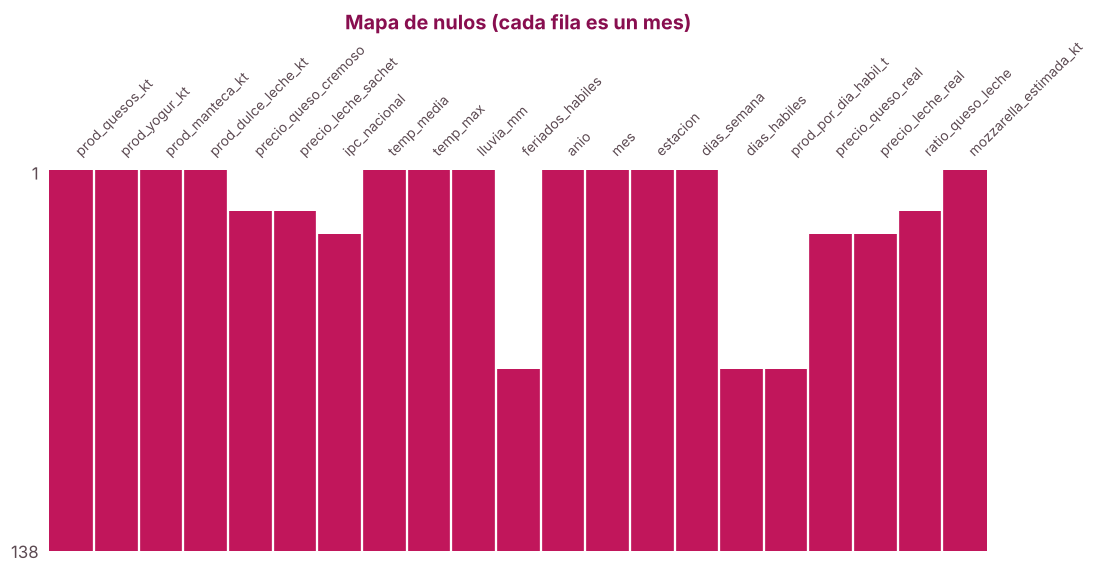

In [5]:
import missingno as msno

nulos = (df.isnull().mean() * 100).sort_values(ascending=False)
nulos = nulos[nulos > 0]
print('% de nulos por columna:')
print(nulos.round(1).to_string())

msno.matrix(df.set_index('fecha'), color=(0.76, 0.09, 0.36), figsize=(11, 4.5), fontsize=9, sparkline=False)
plt.title('Mapa de nulos (cada fila es un mes)', color=ROSA_OSC, fontweight='bold'); plt.show()

**Lectura de los nulos.** No hay nulos al azar: todos se explican por la fuente de cada dato.
- **Feriados y días hábiles (52%):** la API de feriados empieza en 2021. En la primera entrega vimos que los feriados no explican la producción, así que **no se usan** en el modelo.
- **Precios e IPC (11 a 17%):** las series del INDEC empiezan en 2016. El precio real de la leche se usa en el modelo y sus nulos se **reemplazan con la mediana**, calculada solo con datos de entrenamiento.
- **La variable objetivo (`prod_quesos_kt`) no tiene nulos.**

### 4.3 La variable objetivo: producción mensual de quesos

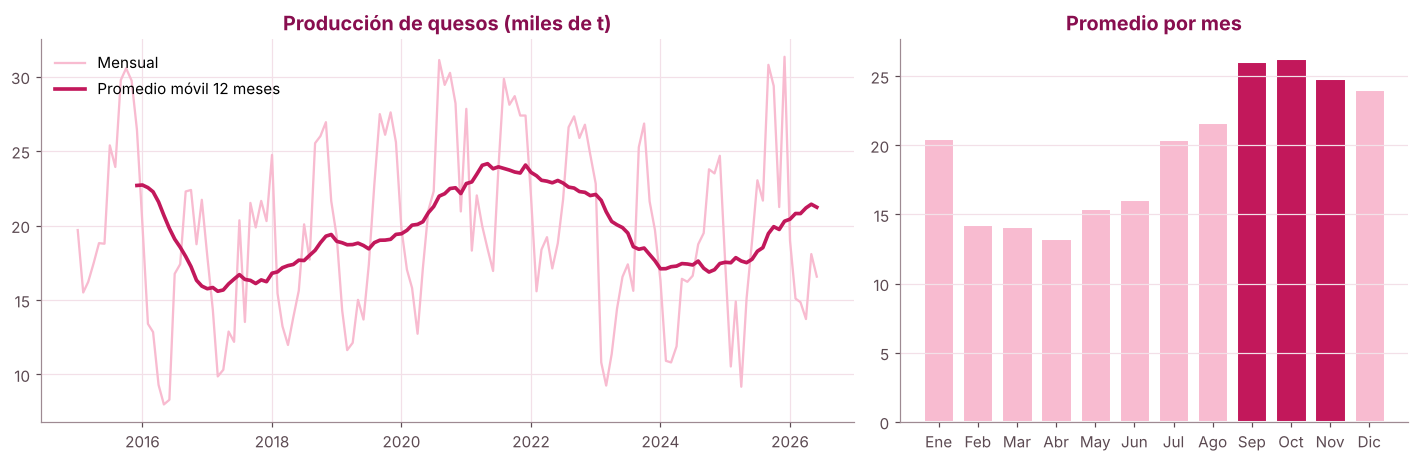

Media: 19.6 kt | desvío: 5.9 kt | pico en Oct (26.3) y mínimo en Abr (13.3)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1.6, 1]})
axes[0].plot(df.fecha, df.prod_quesos_kt, color=ROSA_CLARO, lw=1.5, label='Mensual')
axes[0].plot(df.fecha, df.prod_quesos_kt.rolling(12).mean(), color=ROSA, lw=2.4, label='Promedio móvil 12 meses')
axes[0].set_title('Producción de quesos (miles de t)'); axes[0].legend(loc='upper left')
prom = df.groupby('mes').prod_quesos_kt.mean()
axes[1].bar(MESES, prom.values, color=[ROSA if m in prom.nlargest(3).index else ROSA_CLARO for m in prom.index], edgecolor='white', linewidth=2)
axes[1].set_title('Promedio por mes'); axes[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
print(f'Media: {df.prod_quesos_kt.mean():.1f} kt | desvío: {df.prod_quesos_kt.std():.1f} kt | '
      f'pico en {MESES[prom.idxmax()-1]} ({prom.max():.1f}) y mínimo en {MESES[prom.idxmin()-1]} ({prom.min():.1f})')

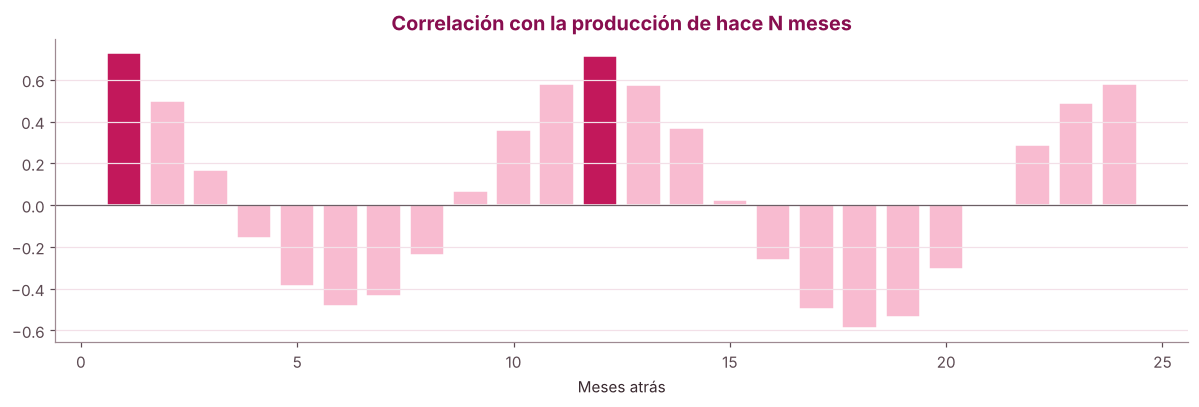

Correlación con el mes anterior: 0.73 | con el mismo mes del año anterior: 0.71


In [7]:
# ¿Qué tanto se parece la producción de un mes a la de meses anteriores? (autocorrelación)
autocorr = pd.Series({l: df.prod_quesos_kt.autocorr(lag=l) for l in range(1, 25)})
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(autocorr.index, autocorr.values, color=[ROSA if l in (1, 12) else ROSA_CLARO for l in autocorr.index], edgecolor='white')
ax.axhline(0, color=GRIS, lw=.8)
ax.set_title('Correlación con la producción de hace N meses'); ax.set_xlabel('Meses atrás'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
print(f'Correlación con el mes anterior: {autocorr[1]:.2f} | con el mismo mes del año anterior: {autocorr[12]:.2f}')

**Conclusión del EDA:** la producción depende fuertemente del **mes del año** y de **lo que se produjo en los meses anteriores**: el mes anterior y el mismo mes del año pasado son los rezagos con más correlación. Esto define la ingeniería de atributos. En la primera entrega vimos que la **temperatura** y los **feriados** no explican la producción, así que quedan afuera.

## 5. Ingeniería de atributos

Solo usamos información que **ya se conoce antes del mes a predecir**, para no "hacer trampa" con datos del futuro (*data leakage*).

| Variable | Tipo | Cómo se construye | Por qué |
|----------|------|-------------------|---------|
| `lag_1`, `lag_2`, `lag_3` | Rezago | Producción de 1, 2 y 3 meses atrás | Inercia de corto plazo |
| `lag_12` | Rezago | Producción del mismo mes del año anterior | Estacionalidad |
| `media_3`, `media_12` | Promedio móvil | Promedio de los últimos 3 y 12 meses | Nivel reciente y tendencia anual |
| `var_interanual` | Transformación | Variación % del último mes contra el mismo mes del año anterior | Si el año viene creciendo o cayendo |
| `dulce_leche_lag1` | Rezago de otra serie | Producción de dulce de leche del mes anterior | Otro uso de la leche (r = 0,64 con quesos) |
| `precio_leche_lag1` | Rezago + imputación | Precio real de la leche del mes anterior; nulos → mediana | Costo de la materia prima |
| `mes_sin`, `mes_cos` | Encoding cíclico | Seno y coseno del mes | Diciembre queda "cerca" de enero |
| `estacion_*` | One Hot Encoding | Una columna 0/1 por estación | Variable categórica a numérica |
| `anio` | Numérica | Año | Tendencia de largo plazo |

Después, **todas las variables se estandarizan** con `StandardScaler` (media 0, desvío 1). Es necesario para Ridge, que es sensible a la escala, y no afecta a los modelos de árboles. El escalado va **dentro de un Pipeline**, así se ajusta solo con los datos de entrenamiento de cada fold.

In [8]:
m = df[['fecha', 'anio', 'mes', 'estacion', 'prod_quesos_kt', 'precio_leche_real', 'prod_dulce_leche_kt']].copy()

# Rezagos y promedios móviles de la variable objetivo
for l in [1, 2, 3, 12]:
    m[f'lag_{l}'] = m.prod_quesos_kt.shift(l)
m['media_3'] = m.prod_quesos_kt.shift(1).rolling(3).mean()
m['media_12'] = m.prod_quesos_kt.shift(1).rolling(12).mean()
m['var_interanual'] = m.prod_quesos_kt.shift(1) / m.prod_quesos_kt.shift(13) - 1

# Rezagos de otras series
m['dulce_leche_lag1'] = m.prod_dulce_leche_kt.shift(1)
m['precio_leche_lag1'] = m.precio_leche_real.shift(1)

# Encoding cíclico del mes y One Hot Encoding de la estación
m['mes_sin'] = np.sin(2 * np.pi * m.mes / 12)
m['mes_cos'] = np.cos(2 * np.pi * m.mes / 12)
m = pd.get_dummies(m, columns=['estacion'], prefix='estacion', dtype=int)

# Los primeros 13 meses no tienen rezago anual completo: se descartan
m = m.dropna(subset=['lag_12', 'media_12', 'var_interanual']).reset_index(drop=True)

FEATURES = ['lag_1', 'lag_2', 'lag_3', 'lag_12', 'media_3', 'media_12', 'var_interanual',
            'dulce_leche_lag1', 'precio_leche_lag1', 'mes_sin', 'mes_cos', 'anio'] + \
           [c for c in m.columns if c.startswith('estacion_')]
TARGET = 'prod_quesos_kt'
print(f'Dataset de modelado: {m.shape[0]} meses x {len(FEATURES)} variables')
m[['fecha', TARGET] + FEATURES].head()

Dataset de modelado: 125 meses x 16 variables


,fecha,prod_quesos_kt,lag_1,lag_2,lag_3,lag_12,media_3,media_12,var_interanual,dulce_leche_lag1,precio_leche_lag1,mes_sin,mes_cos,anio,estacion_Invierno,estacion_Otoño,estacion_Primavera,estacion_Verano
0,2016-02-01,13.397,20.057,26.430,29.728,15.502,25.405000,22.719500,0.018484,2.602,NaN,8.660254e-01,5.000000e-01,2016,0,0,0,1
1,2016-03-01,12.845,13.397,20.057,26.430,16.209,19.961333,22.544083,-0.135789,2.349,NaN,1.000000e+00,6.123234e-17,2016,0,1,0,0
2,2016-04-01,9.296,12.845,13.397,20.057,17.480,15.433000,22.263750,-0.207539,2.631,NaN,8.660254e-01,-5.000000e-01,2016,0,1,0,0
3,2016-05-01,7.984,9.296,12.845,13.397,18.816,11.846000,21.581750,-0.468192,2.384,NaN,5.000000e-01,-8.660254e-01,2016,0,1,0,0
4,2016-06-01,8.296,7.984,9.296,12.845,18.776,10.041667,20.679083,-0.575680,2.375,NaN,1.224647e-16,-1.000000e+00,2016,1,0,0,0


### 5.1 Separación en entrenamiento y test

Como son datos en el tiempo, **no se mezclan al azar**:
- **Entrenamiento:** hasta junio de 2024. Acá se hace la validación cruzada y la optimización.
- **Test:** los **últimos 24 meses** (julio de 2024 a junio de 2026). El modelo nunca los ve hasta la evaluación final.

La imputación del precio de la leche usa la mediana **del entrenamiento**, para que no se filtre información del test.

In [9]:
corte = pd.Timestamp('2024-07-01')
train, test = m[m.fecha < corte].copy(), m[m.fecha >= corte].copy()

mediana_precio = train.precio_leche_lag1.median()
for d in (train, test):
    d['precio_leche_lag1'] = d.precio_leche_lag1.fillna(mediana_precio)

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f'Entrenamiento: {X_train.shape} ({train.fecha.min():%m/%Y} a {train.fecha.max():%m/%Y})')
print(f'Test:          {X_test.shape} ({test.fecha.min():%m/%Y} a {test.fecha.max():%m/%Y})')
print('Nulos restantes:', X_train.isnull().sum().sum() + X_test.isnull().sum().sum())

Entrenamiento: (101, 16) (02/2016 a 06/2024)
Test:          (24, 16) (07/2024 a 06/2026)
Nulos restantes: 0


In [10]:
# Efecto de la estandarización (se muestra con el train completo solo como ilustración)
escalado = pd.DataFrame(StandardScaler().fit_transform(X_train), columns=FEATURES)
pd.DataFrame({'media antes': X_train.mean(), 'desvío antes': X_train.std(),
              'media después': escalado.mean(), 'desvío después': escalado.std(ddof=0)}).round(2).head(8)

,media antes,desvío antes,media después,desvío después
lag_1,19.29,5.89,-0.0,1.0
lag_2,19.39,5.93,0.0,1.0
lag_3,19.56,5.97,0.0,1.0
lag_12,19.88,5.99,-0.0,1.0
media_3,19.41,5.22,-0.0,1.0
media_12,19.81,2.59,-0.0,1.0
var_interanual,-0.00,0.24,0.0,1.0
dulce_leche_lag1,2.74,0.62,0.0,1.0


## 6. Entrenamiento y testeo con validación cruzada

Usamos **`TimeSeriesSplit` con 5 folds**: cada fold entrena con el pasado y valida con los meses siguientes, como pasaría en la vida real. El gráfico muestra cómo se arma cada fold.

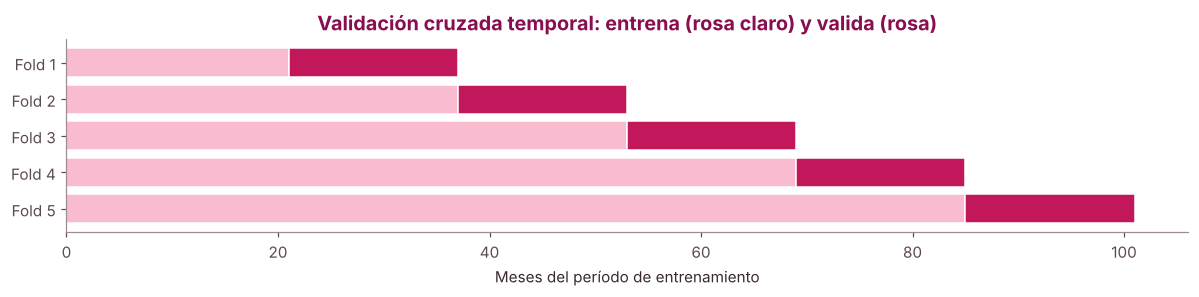

In [11]:
tscv = TimeSeriesSplit(n_splits=5)

fig, ax = plt.subplots(figsize=(11, 2.8))
for i, (tr_idx, va_idx) in enumerate(tscv.split(X_train)):
    ax.barh(i, len(tr_idx), color=ROSA_CLARO, edgecolor='white')
    ax.barh(i, len(va_idx), left=len(tr_idx), color=ROSA, edgecolor='white')
ax.set_yticks(range(5)); ax.set_yticklabels([f'Fold {i+1}' for i in range(5)])
ax.set_xlabel('Meses del período de entrenamiento'); ax.invert_yaxis(); ax.grid(False)
ax.set_title('Validación cruzada temporal: entrena (rosa claro) y valida (rosa)')
plt.tight_layout(); plt.show()

### 6.1 Línea de base

Antes de entrenar, medimos la regla simple: "cada mes se produce lo mismo que el mismo mes del año anterior". Un modelo solo sirve si le gana.

In [12]:
def metricas(y_real, y_pred):
    return {'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)), 'MAE': mean_absolute_error(y_real, y_pred), 'R2': r2_score(y_real, y_pred)}

# Base en validación cruzada (mismos folds) y en test
cv_base = [np.sqrt(mean_squared_error(y_train.iloc[va], X_train.lag_12.iloc[va])) for _, va in tscv.split(X_train)]
base_test = metricas(y_test, X_test.lag_12)
print(f'Base | RMSE validación cruzada: {np.mean(cv_base):.2f} ± {np.std(cv_base):.2f} | '
      f'Test: RMSE {base_test["RMSE"]:.2f}, MAE {base_test["MAE"]:.2f}, R² {base_test["R2"]:.2f}')

Base | RMSE validación cruzada: 3.87 ± 0.78 | Test: RMSE 4.25, MAE 3.47, R² 0.44


### 6.2 Modelos con hiperparámetros por defecto

Entrenamos 4 modelos distintos:
- **Ridge:** regresión lineal con regularización.
- **Random Forest:** ensamble de árboles en paralelo (*bagging*).
- **Gradient Boosting:** ensamble de árboles en serie (*boosting*).
- **XGBoost:** boosting optimizado y regularizado.

In [13]:
modelos = {
    'Ridge':            Pipeline([('escala', StandardScaler()), ('modelo', Ridge())]),
    'Random Forest':    Pipeline([('escala', StandardScaler()), ('modelo', RandomForestRegressor(random_state=SEED))]),
    'Gradient Boosting': Pipeline([('escala', StandardScaler()), ('modelo', GradientBoostingRegressor(random_state=SEED))]),
    'XGBoost':          Pipeline([('escala', StandardScaler()), ('modelo', xgb.XGBRegressor(random_state=SEED, n_jobs=2))]),
}

resultados = []
for nombre, pipe in modelos.items():
    cv = cross_validate(pipe, X_train, y_train, cv=tscv, scoring='neg_root_mean_squared_error')
    pipe.fit(X_train, y_train)
    t = metricas(y_test, pipe.predict(X_test))
    resultados.append({'Modelo': nombre, 'Etapa': 'Por defecto', 'RMSE CV': -cv['test_score'].mean(),
                       'Desvío CV': cv['test_score'].std(), 'RMSE test': t['RMSE'], 'MAE test': t['MAE'], 'R² test': t['R2']})
    print(f'{nombre:18s} RMSE CV {-cv["test_score"].mean():.2f} ± {cv["test_score"].std():.2f} | test RMSE {t["RMSE"]:.2f} | R² {t["R2"]:.2f}')

Ridge              RMSE CV 4.23 ± 1.05 | test RMSE 3.64 | R² 0.59


Random Forest      RMSE CV 4.01 ± 1.01 | test RMSE 3.77 | R² 0.56


Gradient Boosting  RMSE CV 4.23 ± 0.94 | test RMSE 4.01 | R² 0.50


XGBoost            RMSE CV 4.44 ± 1.12 | test RMSE 3.81 | R² 0.55


## 7. Optimización de hiperparámetros

- **Ridge:** `GridSearchCV`, porque tiene un solo hiperparámetro (`alpha`) y se pueden probar todos los valores.
- **Modelos de árboles:** `RandomizedSearchCV` con 30 combinaciones al azar, porque la grilla completa tiene cientos de combinaciones.

Todas las búsquedas usan la misma validación cruzada temporal (5 folds) y buscan el **menor RMSE**.

In [14]:
busquedas = {
    'Ridge': GridSearchCV(
        modelos['Ridge'], {'modelo__alpha': [0.01, 0.1, 1, 3, 10, 30, 100]},
        cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=2),
    'Random Forest': RandomizedSearchCV(
        modelos['Random Forest'],
        {'modelo__n_estimators': [200, 400], 'modelo__max_depth': [3, 5, 8, None],
         'modelo__min_samples_leaf': [1, 2, 4], 'modelo__max_features': ['sqrt', 0.5, 1.0]},
        n_iter=30, cv=tscv, scoring='neg_root_mean_squared_error', random_state=SEED, n_jobs=2),
    'Gradient Boosting': RandomizedSearchCV(
        modelos['Gradient Boosting'],
        {'modelo__n_estimators': [100, 200, 400], 'modelo__learning_rate': [0.01, 0.03, 0.05, 0.1],
         'modelo__max_depth': [2, 3, 4], 'modelo__subsample': [0.7, 0.85, 1.0]},
        n_iter=30, cv=tscv, scoring='neg_root_mean_squared_error', random_state=SEED, n_jobs=2),
    'XGBoost': RandomizedSearchCV(
        modelos['XGBoost'],
        {'modelo__n_estimators': [100, 200, 400], 'modelo__learning_rate': [0.01, 0.03, 0.05, 0.1],
         'modelo__max_depth': [2, 3, 4], 'modelo__subsample': [0.7, 0.85, 1.0],
         'modelo__colsample_bytree': [0.6, 0.8, 1.0], 'modelo__reg_lambda': [0.5, 1, 5]},
        n_iter=30, cv=tscv, scoring='neg_root_mean_squared_error', random_state=SEED, n_jobs=2),
}

optimizados = {}
for nombre, busq in busquedas.items():
    busq.fit(X_train, y_train)
    optimizados[nombre] = busq.best_estimator_
    i = busq.best_index_
    t = metricas(y_test, busq.predict(X_test))
    resultados.append({'Modelo': nombre, 'Etapa': 'Optimizado', 'RMSE CV': -busq.best_score_,
                       'Desvío CV': busq.cv_results_['std_test_score'][i], 'RMSE test': t['RMSE'], 'MAE test': t['MAE'], 'R² test': t['R2']})
    params = {k.replace('modelo__', ''): v for k, v in busq.best_params_.items()}
    print(f'{nombre:18s} RMSE CV {-busq.best_score_:.2f} | test RMSE {t["RMSE"]:.2f} | mejores hiperparámetros: {params}')

Ridge              RMSE CV 3.84 | test RMSE 3.75 | mejores hiperparámetros: {'alpha': 30}


Random Forest      RMSE CV 3.80 | test RMSE 3.51 | mejores hiperparámetros: {'n_estimators': 400, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 8}


Gradient Boosting  RMSE CV 3.85 | test RMSE 3.49 | mejores hiperparámetros: {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 2, 'learning_rate': 0.03}


XGBoost            RMSE CV 3.75 | test RMSE 3.79 | mejores hiperparámetros: {'subsample': 0.85, 'reg_lambda': 0.5, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.6}


### 7.1 Ensamble final: promedio de los modelos optimizados

Como los modelos se equivocan de formas distintas, probamos un **ensamble por votación** (`VotingRegressor`) que promedia las predicciones de los cuatro modelos optimizados. Lo evaluamos con la misma validación cruzada.

In [15]:
voting = VotingRegressor([(n.replace(' ', '_'), est) for n, est in optimizados.items()])
cv = cross_validate(voting, X_train, y_train, cv=tscv, scoring='neg_root_mean_squared_error')
voting.fit(X_train, y_train)
optimizados['Ensamble (promedio)'] = voting
t = metricas(y_test, voting.predict(X_test))
resultados.append({'Modelo': 'Ensamble (promedio)', 'Etapa': 'Optimizado', 'RMSE CV': -cv['test_score'].mean(),
                   'Desvío CV': cv['test_score'].std(), 'RMSE test': t['RMSE'], 'MAE test': t['MAE'], 'R² test': t['R2']})
print(f'Ensamble RMSE CV {-cv["test_score"].mean():.2f} ± {cv["test_score"].std():.2f} | test RMSE {t["RMSE"]:.2f} | R² {t["R2"]:.2f}')

Ensamble RMSE CV 3.68 ± 0.75 | test RMSE 3.53 | R² 0.61


## 8. Selección del mejor modelo

El modelo se elige por el **menor RMSE en validación cruzada**. El test se usa solo para confirmar que el modelo elegido funciona bien con datos que nunca vio. Elegir por el test sería hacer trampa, porque ajustaríamos el modelo a esos 24 meses.

In [16]:
res = pd.DataFrame(resultados)
res.loc[len(res)] = {'Modelo': 'Base: mismo mes año anterior', 'Etapa': '—', 'RMSE CV': np.mean(cv_base), 'Desvío CV': np.std(cv_base),
                     'RMSE test': base_test['RMSE'], 'MAE test': base_test['MAE'], 'R² test': base_test['R2']}
display(res.sort_values('RMSE CV').round(3).reset_index(drop=True))

opt = res[res.Etapa == 'Optimizado'].sort_values('RMSE CV')
MEJOR = opt.iloc[0].Modelo
mejor_modelo = optimizados[MEJOR]
fila = opt.iloc[0]
print(f'\nModelo elegido: {MEJOR}')
print(f'  RMSE CV {fila["RMSE CV"]:.2f} vs {np.mean(cv_base):.2f} de la base | '
      f'test: RMSE {fila["RMSE test"]:.2f}, MAE {fila["MAE test"]:.2f}, R² {fila["R² test"]:.2f}')
print(f'  En test, el error baja un {(1 - fila["RMSE test"] / base_test["RMSE"]) * 100:.0f}% contra la regla "igual que el año anterior"')

,Modelo,Etapa,RMSE CV,Desvío CV,RMSE test,MAE test,R² test
0,Ensamble (promedio),Optimizado,3.680,0.749,3.525,2.868,0.614
1,XGBoost,Optimizado,3.751,0.815,3.789,3.004,0.554
2,Random Forest,Optimizado,3.797,0.877,3.511,2.878,0.617
3,Ridge,Optimizado,3.836,0.404,3.753,3.023,0.563
4,Gradient Boosting,Optimizado,3.850,0.928,3.492,2.813,0.621
5,Base: mismo mes año anterior,—,3.866,0.778,4.246,3.466,0.440
6,Random Forest,Por defecto,4.007,1.008,3.765,2.989,0.560
7,Gradient Boosting,Por defecto,4.231,0.937,4.011,3.180,0.500
8,Ridge,Por defecto,4.233,1.047,3.635,3.081,0.590
9,XGBoost,Por defecto,4.441,1.119,3.812,3.214,0.549



Modelo elegido: Ensamble (promedio)
  RMSE CV 3.68 vs 3.87 de la base | test: RMSE 3.53, MAE 2.87, R² 0.61
  En test, el error baja un 17% contra la regla "igual que el año anterior"


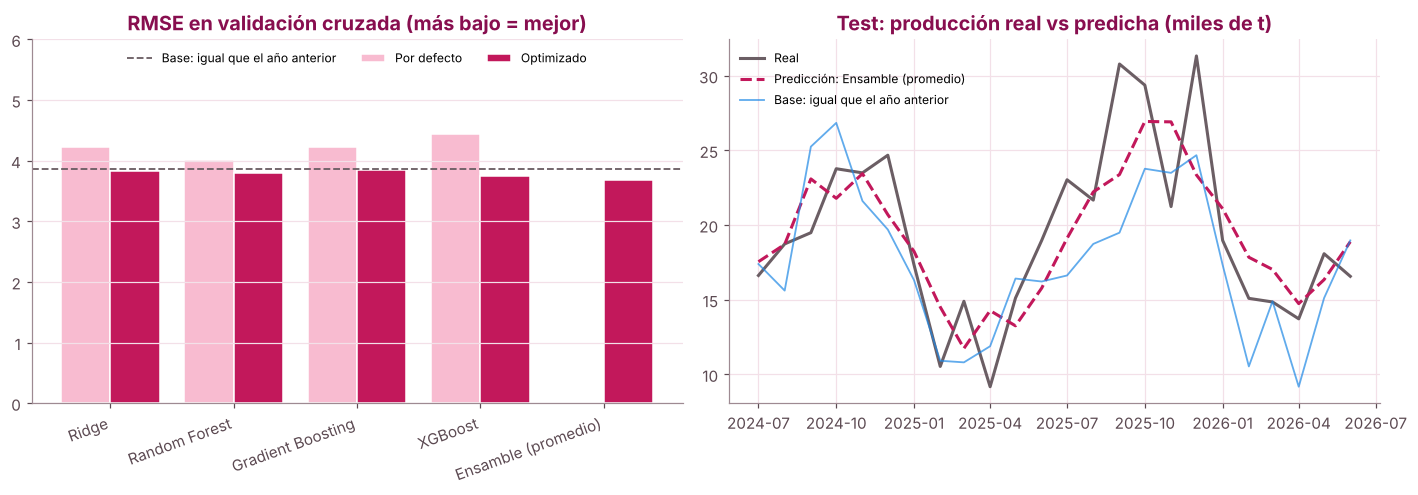

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
pv = res[res.Etapa != '—'].pivot(index='Modelo', columns='Etapa', values='RMSE CV').reindex(list(modelos) + ['Ensamble (promedio)'])
x = np.arange(len(pv))
axes[0].bar(x - 0.2, pv['Por defecto'], 0.4, color=ROSA_CLARO, label='Por defecto', edgecolor='white')
axes[0].bar(x + 0.2, pv['Optimizado'], 0.4, color=ROSA, label='Optimizado', edgecolor='white')
axes[0].axhline(np.mean(cv_base), color=GRIS, ls='--', lw=1.2, label='Base: igual que el año anterior')
axes[0].set_xticks(x); axes[0].set_xticklabels(pv.index, rotation=20, ha='right')
axes[0].set_title('RMSE en validación cruzada (más bajo = mejor)'); axes[0].set_ylim(0, 6)
axes[0].legend(loc='upper center', ncol=3, fontsize=8); axes[0].grid(axis='x', visible=False)

y_pred_test = mejor_modelo.predict(X_test)
axes[1].plot(test.fecha, y_test, color=GRIS, lw=2, label='Real')
axes[1].plot(test.fecha, y_pred_test, color=ROSA, lw=2, ls='--', label=f'Predicción: {MEJOR}')
axes[1].plot(test.fecha, X_test.lag_12, color=AZUL, lw=1.2, alpha=.7, label='Base: igual que el año anterior')
axes[1].set_title('Test: producción real vs predicha (miles de t)'); axes[1].legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.savefig('images/15_seleccion_modelo.png', bbox_inches='tight'); plt.show()

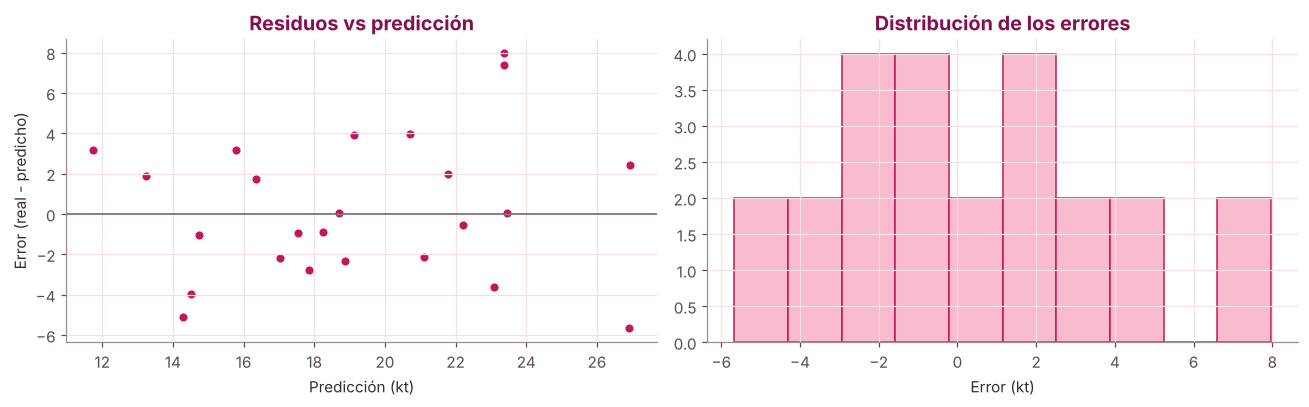

Error medio: +0.28 kt (cerca de 0 = sin sesgo) | en el 58% de los meses el error es de 3 mil t o menos


In [18]:
# Análisis de residuos del modelo elegido
residuos = y_test - y_pred_test
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(y_pred_test, residuos, color=ROSA, s=40, edgecolor='white')
axes[0].axhline(0, color=GRIS, lw=1); axes[0].set_xlabel('Predicción (kt)'); axes[0].set_ylabel('Error (real - predicho)')
axes[0].set_title('Residuos vs predicción')
axes[1].hist(residuos, bins=10, color=ROSA_CLARO, edgecolor=ROSA)
axes[1].set_title('Distribución de los errores'); axes[1].set_xlabel('Error (kt)')
plt.tight_layout(); plt.show()
print(f'Error medio: {residuos.mean():+.2f} kt (cerca de 0 = sin sesgo) | '
      f'en el {(residuos.abs() <= 3).mean():.0%} de los meses el error es de 3 mil t o menos')

## 9. ¿Qué variables pesan más? (SHAP)

**SHAP** muestra cuánto empuja cada variable la predicción hacia arriba o hacia abajo. Lo calculamos sobre el **mejor modelo de árboles optimizado**, porque SHAP tiene un método exacto y rápido para árboles (`TreeExplainer`).

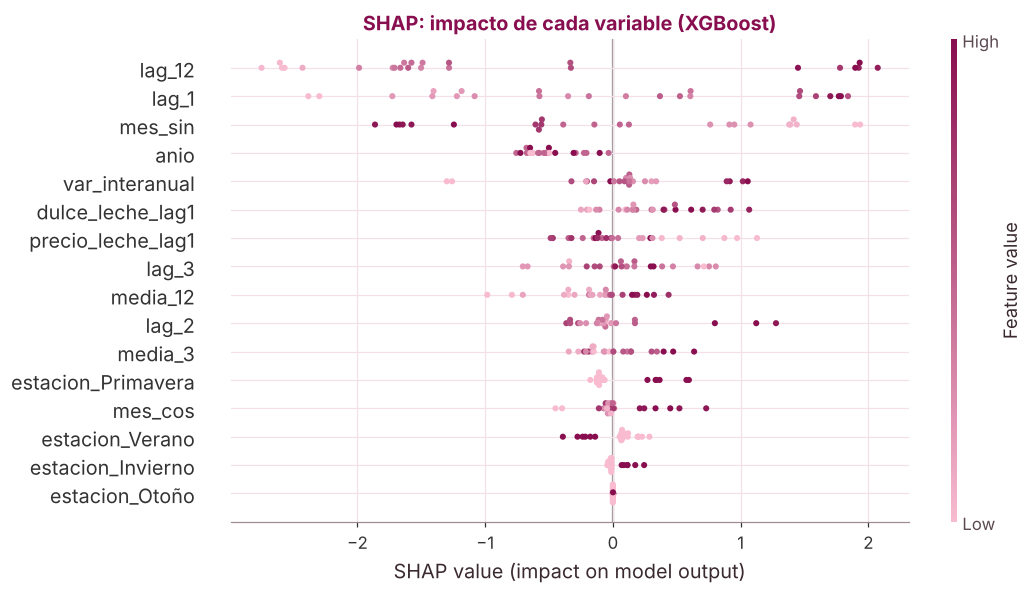

Importancia media (|SHAP|, miles de t):
lag_12              1.75
lag_1               1.18
mes_sin             1.08
anio                0.50
var_interanual      0.39
dulce_leche_lag1    0.38


In [19]:
arboles = opt[opt.Modelo.isin(['Random Forest', 'Gradient Boosting', 'XGBoost'])].iloc[0].Modelo
pipe = optimizados[arboles]
X_test_esc = pd.DataFrame(pipe.named_steps['escala'].transform(X_test), columns=FEATURES)
explainer = shap.TreeExplainer(pipe.named_steps['modelo'])
shap_values = explainer.shap_values(X_test_esc)

plt.figure()
shap.summary_plot(shap_values, X_test_esc, show=False, plot_size=(10, 5.5), cmap=LinearSegmentedColormap.from_list('rosa', [ROSA_CLARO, ROSA_OSC]))
plt.title(f'SHAP: impacto de cada variable ({arboles})', color=ROSA_OSC, fontweight='bold')
plt.tight_layout(); plt.savefig('images/16_shap.png', bbox_inches='tight'); plt.show()

imp = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print('Importancia media (|SHAP|, miles de t):')
print(imp.round(2).head(6).to_string())

## 10. Pronóstico de los próximos 6 meses

Reentrenamos el modelo elegido con **todos** los datos (entrenamiento + test) y pronosticamos de julio a diciembre de 2026, que todavía no se publicaron. Como cada mes usa los anteriores, el pronóstico se hace **mes a mes**: la predicción de julio entra como dato para predecir agosto, y así sigue.

Para las otras series (dulce de leche y precio de la leche) se repite el último valor conocido.

,mes,pronostico_kt,mismo_mes_anio_anterior_kt,rango_probable_kt
0,Jul 2026,20.4,23.0,17 a 24
1,Ago 2026,22.6,21.7,19 a 26
2,Sep 2026,27.0,30.8,23 a 31
3,Oct 2026,26.3,29.4,23 a 30
4,Nov 2026,25.0,21.2,22 a 29
5,Dic 2026,23.7,31.3,20 a 27


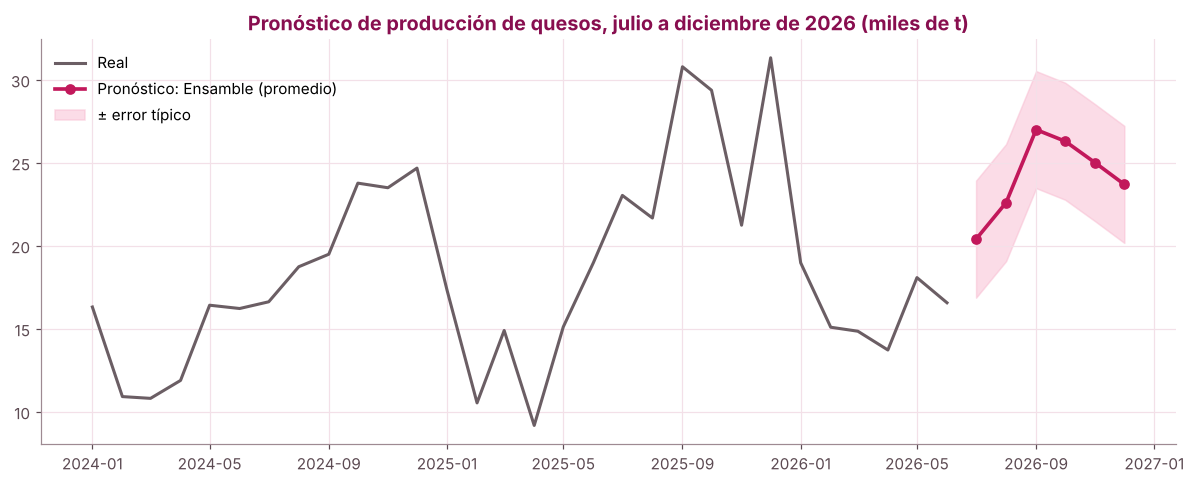

In [20]:
from sklearn.base import clone
X_all = pd.concat([X_train, X_test]); y_all = pd.concat([y_train, y_test])
final = clone(mejor_modelo).fit(X_all, y_all)

hist = df.set_index('fecha').prod_quesos_kt.copy()
dulce = df.prod_dulce_leche_kt.dropna().iloc[-1]
precio = df.precio_leche_real.dropna().iloc[-1]
ESTACION = {12: 'Verano', 1: 'Verano', 2: 'Verano', 3: 'Otoño', 4: 'Otoño', 5: 'Otoño',
            6: 'Invierno', 7: 'Invierno', 8: 'Invierno', 9: 'Primavera', 10: 'Primavera', 11: 'Primavera'}
filas = []
for fecha in pd.date_range(hist.index.max() + pd.offsets.MonthBegin(1), periods=6, freq='MS'):
    a1 = fecha - pd.DateOffset(years=1)
    x = {'lag_1': hist.iloc[-1], 'lag_2': hist.iloc[-2], 'lag_3': hist.iloc[-3], 'lag_12': hist.loc[a1],
         'media_3': hist.iloc[-3:].mean(), 'media_12': hist.iloc[-12:].mean(),
         'var_interanual': hist.iloc[-1] / hist.loc[hist.index[-1] - pd.DateOffset(years=1)] - 1,
         'dulce_leche_lag1': dulce, 'precio_leche_lag1': precio,
         'mes_sin': np.sin(2 * np.pi * fecha.month / 12), 'mes_cos': np.cos(2 * np.pi * fecha.month / 12), 'anio': fecha.year}
    for e in ['Invierno', 'Otoño', 'Primavera', 'Verano']:
        x[f'estacion_{e}'] = int(ESTACION[fecha.month] == e)
    pred = final.predict(pd.DataFrame([x])[FEATURES])[0]
    hist.loc[fecha] = pred
    filas.append({'mes': f'{MESES[fecha.month-1]} {fecha.year}', 'pronostico_kt': round(pred, 1),
                  'mismo_mes_anio_anterior_kt': round(hist.loc[a1], 1),
                  'rango_probable_kt': f'{pred - fila["RMSE test"]:.0f} a {pred + fila["RMSE test"]:.0f}'})
pronostico = pd.DataFrame(filas)
pronostico.to_csv('data/processed/pronostico_entrega_final.csv', index=False)
display(pronostico)

fig, ax = plt.subplots()
h = df[df.fecha >= '2024-01-01']
fechas_f = pd.date_range(df.fecha.max() + pd.offsets.MonthBegin(1), periods=6, freq='MS')
ax.plot(h.fecha, h.prod_quesos_kt, color=GRIS, lw=2, label='Real')
ax.plot(fechas_f, pronostico.pronostico_kt, color=ROSA, lw=2.4, marker='o', label=f'Pronóstico: {MEJOR}')
ax.fill_between(fechas_f, pronostico.pronostico_kt - fila['RMSE test'], pronostico.pronostico_kt + fila['RMSE test'],
                color=ROSA_CLARO, alpha=.5, label='± error típico')
ax.set_title('Pronóstico de producción de quesos, julio a diciembre de 2026 (miles de t)'); ax.legend(loc='upper left')
plt.tight_layout(); plt.savefig('images/17_pronostico_final.png', bbox_inches='tight'); plt.show()

## 11. Conclusiones

### Respuestas a las preguntas

1. **¿El modelo le gana a la regla simple?** Sí. El modelo elegido, un **ensamble que promedia los cuatro modelos optimizados**, comete menos error que la regla "igual que el mismo mes del año anterior":
   - En validación cruzada: RMSE de **3,68** contra **3,87** de la regla (5% menos).
   - En el test de los últimos 24 meses: RMSE de **3,53** contra **4,25** (**17% menos**). Explica el **61%** de la variación mensual (R²), contra el 44% de la regla.
2. **¿Lineal o ensamble?** Sin optimizar, **ningún modelo superaba a la regla** en validación cruzada. Ya optimizados, los cuatro quedan muy parejos (RMSE entre 3,75 y 3,85):
   - Ridge es el más **estable**: tiene el menor desvío entre folds.
   - XGBoost es el mejor modelo individual.
   - **Promediarlos** da el mejor resultado, porque cada modelo se equivoca en meses distintos.
3. **¿Cuánto aporta la optimización?** Baja el RMSE de validación cruzada entre un **5% y un 16%** según el modelo, y XGBoost es el que más mejora (de 4,44 a 3,75). Sin optimización, el Machine Learning no servía.
4. **¿Qué variables pesan más?** Según SHAP sobre XGBoost, pesan sobre todo **lo producido el mismo mes del año anterior**, **lo producido el mes anterior** y **el mes del año**. El modelo combina **estacionalidad + inercia**, tal como anticipó el EDA de la primera entrega.

### Qué significa para Nido Mozzarella

- El pronóstico para la segunda mitad de 2026 marca la **suba de primavera**: unos **27 mil toneladas en septiembre**, con un rango probable de 23 a 31. Ese es el momento de mayor oferta de queso y de leche en el mercado.
- **Compras:** conviene asegurar volumen de leche para septiembre a noviembre, cuando hay más disponible.
- **Comercial:** con mucha oferta en primavera y verano, la presión sobre el precio es a la baja, así que es mejor apostar a volumen y promociones. En otoño-invierno, con menos oferta, hay más espacio para recomponer precios.
- El modelo se puede **reentrenar cada mes** con el dato nuevo del INDEC para actualizar el pronóstico.

### Limitaciones y próximos pasos

- Son **125 meses** de datos: alcanza para modelos chicos, pero el error típico sigue siendo de unas **3,5 mil toneladas por mes**, el ±18% de un mes promedio.
- El modelo **no anticipa shocks** como la inundación de 2016 en la cuenca lechera.
- El pronóstico a 6 meses acumula error, porque cada mes usa la predicción del anterior.
- **Para mejorarlo:**
  - Sumar la **leche cruda que reciben las industrias** (OCLA) y el **precio al productor**, que anticipan la producción de queso.
  - Sumar las **lluvias en la cuenca lechera**, en lugar de las de Buenos Aires.